In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import os
print(os.getcwd())

C:\Users\Sophia


In [8]:

import pandas as pd

df = pd.read_excel(
    r"C:\Users\Sophia\Desktop\Python Homework\Time_Series_Dataset.xlsx",
    sheet_name="Raw_Data"
)

display(df.head())


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,"Apr 01, 2016","67,422.45",706,"8,069",18.0,No
1,01/06/2023,"154,266.93",1534,"10,400",48.0,Yes
2,"Aug 01, 2019","EGP 113,142.94",1214,"9,903",42.0,No
3,01 Nov 2019,NaN,964,"13,146",15.0,Yes
4,"Dec 01, 2017","79,084.17",858,"11,785",26.0,Yes


In [10]:
# Part 1 - Question 1: Data inspection

print("FIRST 5 ROWS")
display(df.head())

print("LAST 5 ROWS")
display(df.tail())

print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

FIRST 5 ROWS


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,"Apr 01, 2016","67,422.45",706,"8,069",18.0,No
1,01/06/2023,"154,266.93",1534,"10,400",48.0,Yes
2,"Aug 01, 2019","EGP 113,142.94",1214,"9,903",42.0,No
3,01 Nov 2019,NaN,964,"13,146",15.0,Yes
4,"Dec 01, 2017","79,084.17",858,"11,785",26.0,Yes


LAST 5 ROWS


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
117,01 Nov 2017,"EGP 76,684.45",764,"10,998",19.0,Yes
118,2019-09-01,"101,628.12","1,121","8,703",27.0,No
119,01 Mar 2021,"121,965.57","1,464","9,984",40.0,Yes
120,2024-09-01,"135,468.09",NaN,"11,109",55.0,No
121,2017-09-01,"74,897.96",780,"EGP 7,090",19.0,No


DATASET SHAPE
(122, 6)

COLUMN NAMES
['Date', 'Revenue_EGP', 'Orders', 'Marketing_Spend_EGP', 'Returns_Count', 'Promotion']

DATA TYPES


Date                    object
Revenue_EGP             object
Orders                  object
Marketing_Spend_EGP     object
Returns_Count          float64
Promotion               object
dtype: object


MISSING VALUES


Date                   0
Revenue_EGP            3
Orders                 3
Marketing_Spend_EGP    2
Returns_Count          2
Promotion              0
dtype: int64

In [15]:
# Part 1- Question 2: Date Conversion and Duplicate Checks

# Convert mixed date formats into datatime
df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

# Check dates that could not be converted
print("Invalid Dates")
print(df["Date"].isna().sum())

# Convert dates to the first day of each month
df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# Sort data chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Check repeated months
print("\nDUPLICATE MONTHS")
print(df["Date"].duplicated().sum())

# Display records with repeated months
print("\REPEATED MONTH RECORDS")
display(df["Date"].duplicated().sum())

# Display records with repeated months
print("\nREPEATED MONTH RECORDS")
display(df[df["Date"].duplicated(keep=False)])


# Check fully duplicated rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Display first five rows after sorting
print("\nFIRST 5 ROWS AFTER SORTING")
display(df.head())

Invalid Dates
0

DUPLICATE MONTHS
32
\REPEATED MONTH RECORDS


np.int64(32)


REPEATED MONTH RECORDS


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,"85,835.65",985,"EGP 8,602",28.0,Yes
1,2016-01-01,"EGP 69,450.01",724,"8,177",31.0,No
2,2016-01-01,"70,479.47",775,"EGP 6,471",34.0,No
3,2016-01-01,NaN,720,"12,282",12.0,No
12,2017-01-01,"79,730.07",859,"8,313",21.0,No
13,2017-01-01,"100,658.89",1070,"7,156",13.0,Yes
14,2017-01-01,"EGP 88,093.97",920,"8,526",29.0,No
15,2017-01-01,"70,190.99",827,"11,755",33.0,No
24,2018-01-01,"EGP 88,027.65",835,"EGP 7,572",17.0,No
25,2018-01-01,"101,730.91",1112,"8,641",25.0,Yes



DUPLICATE ROWS
2

FIRST 5 ROWS AFTER SORTING


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,"85,835.65",985,"EGP 8,602",28.0,Yes
1,2016-01-01,"EGP 69,450.01",724,"8,177",31.0,No
2,2016-01-01,"70,479.47",775,"EGP 6,471",34.0,No
3,2016-01-01,NaN,720,"12,282",12.0,No
4,2016-03-01,"74,929.98",873,"6,123",10.0,Yes


In [17]:

# Part 1 - Question 2: Correct Mixed Date Formats

# Reload original dataset
df = pd.read_excel(
    r"C:\Users\Sophia\Desktop\Python Homework\Time_Series_Dataset.xlsx",
    sheet_name="Raw_Data"
)

# Convert mixed dates using day-first interpretation
df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)


# Standardize to beginning of each month
df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Check results
print("INVALID DATES")
print(df["Date"].isna().sum())

print("\nDUPLICATE MONTHS")
print(df["Date"].duplicated().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nREPEATED MONTH RECORDS")
display(df[df["Date"].duplicated(keep=False)])

print("\nFIRST 5 ROWS")
display(df.head())

INVALID DATES
0

DUPLICATE MONTHS
2

DUPLICATE ROWS
2

REPEATED MONTH RECORDS


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
28,2018-05-01,"EGP 103,372.52","1,083","9,631",20.0,No
29,2018-05-01,"EGP 103,372.52","1,083","9,631",20.0,No
94,2023-10-01,"130,170.28",1262,"14,767",37.0,No
95,2023-10-01,"130,170.28",1262,"14,767",37.0,No



FIRST 5 ROWS


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,"70,479.47",775,"EGP 6,471",34.0,No
1,2016-02-01,"EGP 69,450.01",724,"8,177",31.0,No
2,2016-03-01,"74,929.98",873,"6,123",10.0,Yes
3,2016-04-01,"67,422.45",706,"8,069",18.0,No
4,2016-05-01,"EGP 81,851.94",804,"7,516",15.0,No


In [23]:
# Part 1- Question 3: Remove Duplicates and Convert Numeric COlumns

# Save data types before cleaning
dtypes_before = df.dtypes.astype(str)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("SHAPE AFTER REMOVING DUPLICATES")
print(df.shape)

# Define numeric columns
numeric_cols = [
    "Revenue_EGP",
    "Orders",
    "Marketing_Spend_EGP",
    "Returns_Count"
]

# Clean and convert numeric columns
for col in numeric_cols:
    df[col] = (
        df[col]
        .astype("string")
        .str.replace("EGP", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Compare data types before and after
dtypes_after = df.dtypes.astype(str)

dtype_comparison = pd.DataFrame({
        "Before":dtypes_before,
        "After": dtypes_after
})

print("\nDATA TYPE COMPARISON")
display(dtype_comparison)

#Check missing values
print("\nMISsiNG VALUES AFTER COMVERSION")
print(df.isna().sum())

# Display first five cleaned rows
print("\nFIRST 5 ROWS")
display(df.head())

SHAPE AFTER REMOVING DUPLICATES
(120, 6)

DATA TYPE COMPARISON


,Before,After
Date,datetime64[ns],datetime64[ns]
Revenue_EGP,Float64,Float64
Orders,Int64,Int64
Marketing_Spend_EGP,Int64,Int64
Returns_Count,float64,Float64
Promotion,object,object



MISsiNG VALUES AFTER COMVERSION


Date                   0
Revenue_EGP            3
Orders                 3
Marketing_Spend_EGP    2
Returns_Count          2
Promotion              0
dtype: int64


FIRST 5 ROWS


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,70479.47,775,6471,34.0,No
1,2016-02-01,69450.01,724,8177,31.0,No
2,2016-03-01,74929.98,873,6123,10.0,Yes
3,2016-04-01,67422.45,706,8069,18.0,No
4,2016-05-01,81851.94,804,7516,15.0,No


In [3]:

import pandas as pd

# Reload original dataset
df = pd.read_excel(
    r"C:\Users\Sophia\Desktop\Python Homework\Time_Series_Dataset.xlsx",
    sheet_name="Raw_Data"
)

# Convert dates
df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Standardize dates and sort
df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df = df.sort_values("Date").drop_duplicates().reset_index(drop=True)

# Convert numeric columns
numeric_cols = [
    "Revenue_EGP",
    "Orders",
    "Marketing_Spend_EGP",
    "Returns_Count"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype("string")
        .str.replace("EGP", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

print("DATA READY!")
print(df.shape)


DATA READY!
(120, 6)


In [6]:

# Restore Date as a regular column if it is the index
if df.index.name == "Date":
    df = df.reset_index()

# Set Date as the monthly index
df = df.set_index("Date").sort_index()

print("DATE INDEX CHECK")
print(df.index.name)

print("\nFIRST 5 ROWS")
display(df.head())


DATE INDEX CHECK
Date

FIRST 5 ROWS


,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
Date,,,,,
2016-01-01,70479.47,775.0,6471.0,34.0,No
2016-02-01,69450.01,724.0,8177.0,31.0,No
2016-03-01,74929.98,873.0,6123.0,10.0,Yes
2016-04-01,67422.45,706.0,8069.0,18.0,No
2016-05-01,81851.94,804.0,7516.0,15.0,No


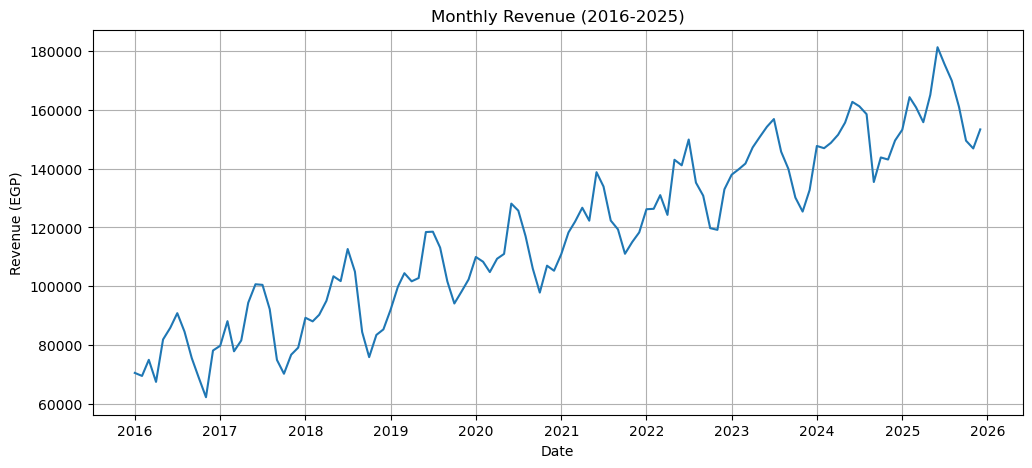

FIRST 5 LOG RETURNS


Date
2016-02-01    -1.471425
2016-03-01     7.594686
2016-04-01   -10.557603
2016-05-01    19.393396
2016-06-01     4.752242
Name: Log_Returns, dtype: float64


NUMBER OF RETURNS
119


In [11]:
# ARCH/ GARCH Homework 02

# Part 1 - Question 3: Calcualte Monthly Log Returns

import numpy as np
import matplotlib.pyplot as plt

# Plot monthly revenue
plt.figure(figsize=(12,5))
plt.plot(df.index, df["Revenue_EGP"])
plt.title("Monthly Revenue (2016-2025)")
plt.xlabel("Date")
plt.ylabel("Revenue (EGP)")
plt.grid(True)
plt.show()

# Caluclate monthly percentage log returns
df["Log_Returns"] = 100 * np.log(
    df["Revenue_EGP"] / df["Revenue_EGP"].shift(1)
)

# Remove the first undefined returns
returns = df["Log_Returns"].dropna().astype(float)

print("FIRST 5 LOG RETURNS")
display(returns.head())

print("\nNUMBER OF RETURNS")
print(len(returns))

In [13]:
# Part 1 - Question 4: Train/ Test Split

# Split monthly log returns chronologically
train_returns = returns.loc[: "2024-12-01"]
test_returns = returns.loc["2052-01-01":"2052-12-01"]

print("TRAINING PERIOD")
print(train_returns.index.min(), "to", train_returns.index.max())

print("\nTESTING PERIOD")
print(test_returns.index.min(), "to", test_returns.index.max())

print("\nTRAINING OBSERVATIONS")
print(len(train_returns))

print("\nTESTING OBSERVATIONS")
print(len(test_returns))

# Display first five training
print("\nFIRST 5 TRAINING RETURNS")
display(train_returns.head())

# Display test returns
print("\nTEST RETURNS")
display(test_returns)

TRAINING PERIOD
2016-02-01 00:00:00 to 2024-12-01 00:00:00

TESTING PERIOD
NaT to NaT

TRAINING OBSERVATIONS
107

TESTING OBSERVATIONS
0

FIRST 5 TRAINING RETURNS


Date
2016-02-01    -1.471425
2016-03-01     7.594686
2016-04-01   -10.557603
2016-05-01    19.393396
2016-06-01     4.752242
Name: Log_Returns, dtype: float64


TEST RETURNS


Series([], Name: Log_Returns, dtype: float64)

In [14]:
# Check the dates in the returns series

print("FIRST DATE:", returns.index.min())
print("LAST DATE:", returns.index.max())

print("\nLAST 15 RETURNS")
display(returns.tail(15))

print("\nINDEX TYPE")
print(type(returns.index))

FIRST DATE: 2016-02-01 00:00:00
LAST DATE: 2025-12-01 00:00:00

LAST 15 RETURNS


Date
2024-10-01    5.991387
2024-11-01   -0.493545
2024-12-01    4.425334
2025-01-01    2.427398
2025-02-01    6.979490
2025-03-01   -2.141791
2025-04-01   -3.184829
2025-05-01    5.810074
2025-06-01    9.361018
2025-07-01   -3.249941
2025-08-01   -3.236135
2025-09-01   -5.406704
2025-10-01   -7.397264
2025-11-01   -1.786748
2025-12-01    4.323474
Name: Log_Returns, dtype: float64


INDEX TYPE
<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [16]:
# Split trainngi and testing data by year

train_returns = returns[returns.index.year <=2024 ]
test_returns = returns[returns.index.year == 2025]

print("TRAINING OBSERVATIONS:", len(train_returns))
print("TESTING OBSERVATIONS:", len(test_returns))

print("\n2025 TEST RETURNS")
display(test_returns)

TRAINING OBSERVATIONS: 107
TESTING OBSERVATIONS: 12

2025 TEST RETURNS


Date
2025-01-01    2.427398
2025-02-01    6.979490
2025-03-01   -2.141791
2025-04-01   -3.184829
2025-05-01    5.810074
2025-06-01    9.361018
2025-07-01   -3.249941
2025-08-01   -3.236135
2025-09-01   -5.406704
2025-10-01   -7.397264
2025-11-01   -1.786748
2025-12-01    4.323474
Name: Log_Returns, dtype: float64

In [17]:
# Part 1 - Question 5: ADF Stationarity Test

from statsmodels.tsa.stattools import adfuller

# Run ADF test on training log returns
adf_result = adfuller(train_returns.dropna())

# Display results
print("ADF TEST RESULTS")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("]nCRITCAL VALUES")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

# Interpret the test
print("\nCONCLUSION")

if adf_result[1] < 0.05:
    print("Reject H0: THe return series is stationariy.")
else:
    print("Fail to reject H0: The return series may be non-stationary.")

ADF TEST RESULTS
ADF Statistic: -9.540120720520248
p-value: 2.7409452591049286e-16
Number of Lags: 10
Number of Observations: 96
]nCRITCAL VALUES
1%: -3.5003788874873405
5%: -2.8921519665075235
10%: -2.5830997960069446

CONCLUSION
Reject H0: THe return series is stationariy.


In [ ]:
# The Augmented Dickey -Fuller test produces a static of -9.5401 and a p-value of 
# approximately 2.74 x 10^(-16). Since the p-value is below 0.05, we reject the 
# null hypothesi sof a unit root. The results provide strong evidence that the 
# monthly revenue log-return series is stationary in its mean, supporting its use
# in subsequent ARCH/ GARCH analysis 

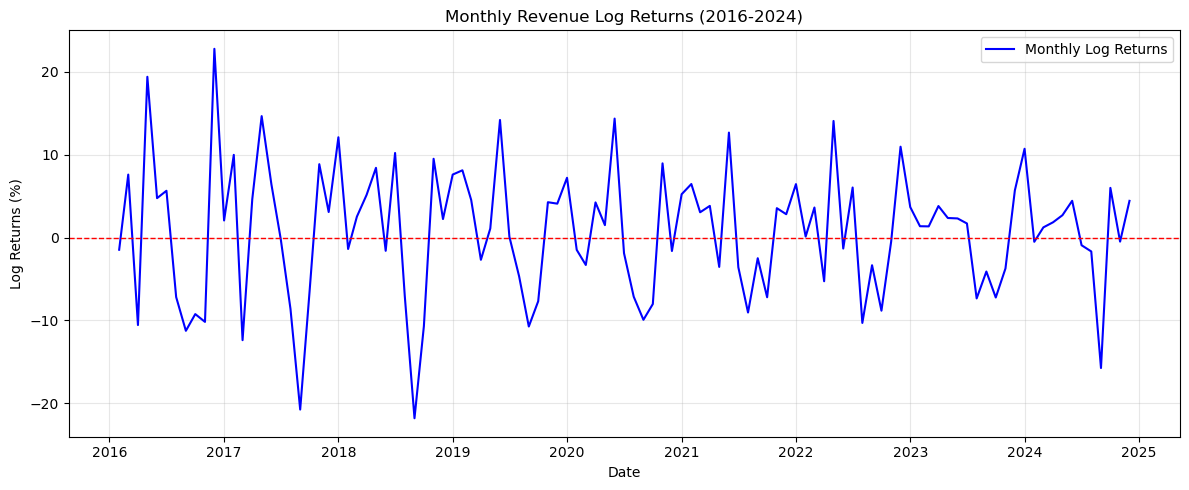

In [20]:
# Part 2 - Question 6: Plot Training Returns

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    train_returns.index,
    train_returns,
    color="blue",
    linewidth=1.5,
    label="Monthly Log Returns"
)

plt.axhline(y=0, color="red", linestyle="--", linewidth=1)

plt.title("Monthly Revenue Log Returns (2016-2024)")
plt.xlabel("Date")
plt.ylabel("Log Returns (%)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:
# The monthly revenue log-return series fluctuates around zero without ac lear long-term
# upward or downward trend. Several large positive and negative changes occur between 2016 and 2018,
# while some later periods exhibit relatively smaller fluctuations. However, occasional
# large shocks remain visible throughout the sample, including a substantial negative return 
# in late 2024.

# These patterns suggest that the magnitude of monthly revenue changes may vary
# over time. Although the plot provides some visual indications of volatility clustering,
# the evidence is not conclusive. Further analysis using squared returns, rolling 
# standard deviations, and teh ARCH-LM test is necessary to detremine whether
# significant conditional hetreoskedasticity is present. 

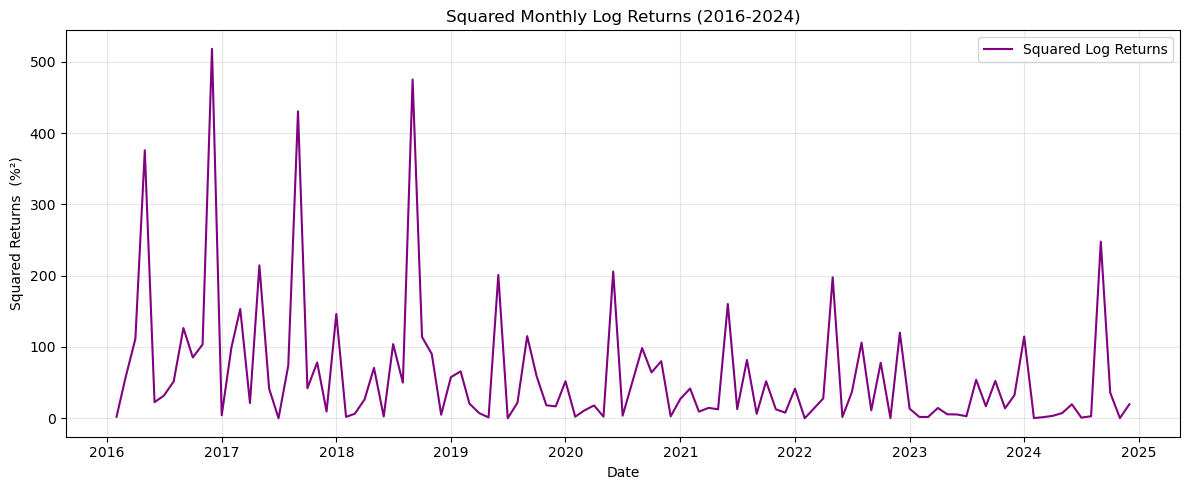

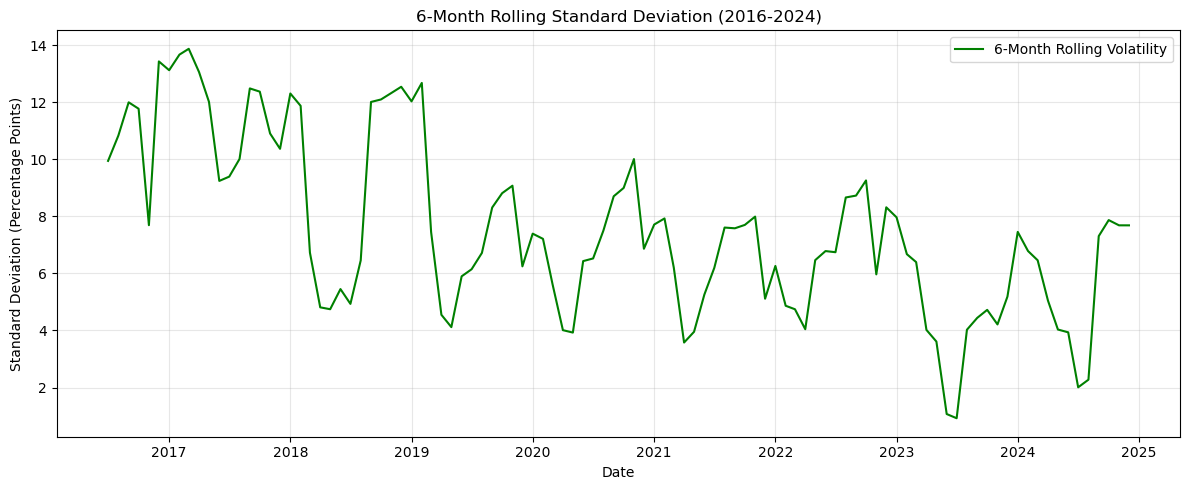

In [24]:
# Part 2 - Question 7: Volatility Diagnostic

import matplotlib.pyplot as plt

# Calculate squared returns
squared_returns = train_returns ** 2

# Calculate 6-month rolling standard deviation
rolling_volatility = train_returns.rolling(window=6).std()

# Plot squared returns
plt.figure(figsize=(12, 5))

plt.plot(
    squared_returns.index,
    squared_returns,
    color="purple",
    label="Squared Log Returns"
)

plt.title("Squared Monthly Log Returns (2016-2024)")
plt.xlabel("Date")
plt.ylabel("Squared Returns  (%²)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot rolling standard devaition
plt.figure(figsize=(12, 5))

plt.plot(
    rolling_volatility.index,
    rolling_volatility,
    color="green",
    label="6-Month Rolling Volatility"
)


plt.title("6-Month Rolling Standard Deviation (2016-2024)")
plt.xlabel("Date")
plt.ylabel("Standard Deviation (Percentage Points)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()





           

In [ ]:
# The six-month rolling standard eviation indicates that the variability of 
# monthly revenue log returns changes over time. Volatility was relatively high
# during 2016-2017, reaching approximately 14 percentage points. It fluctuated 
# at moderate levels during 2019-2022 and declined sharply in mid-2023.
# By late 2024, volatility had increased again to approximately 8 percentage points
# These result suggest that the magnitude of revenue growth fluctuations is not
# constant across the sample. Howevre, rolling volatility alone does not establish
# statistically significant ARCH effects. An ARCH-LM test is required to access
# whether past shocks help explain subsequent conditional variance. 
# Overall, the magnitude of monthly revenue growth fluctuations appears to decline
# over the sample, although volatility increase sagain in certain periods, particularly
# toward late 2024. 

In [26]:
# Part 2- Question 8: ARCH - LM Test

from statsmodels.stats.diagnostic import het_arch

# Convert training returns to float
train_returns = train_returns.astype(float)

# Remove the training mean
residuals = train_returns - train_returns.mean()

# Run ARCH - LM test with 6 lags
lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
    residuals,
    nlags=6
)

print("ARCH-LM TEST RESULTS")
print("LM Statistics:", lm_stat)
print("LM p-value:", lm_pvalue)
print("F Statistic:", f_stat)
print("F p-value:", f_pvalue)

print("\nCONCLUSION")

if lm_pvalue < 0.05:
    print("Reject H0: Evidence of ARCH effects.")
else:
    print("Fail to reject H0: Insufficient evidence of ARCH effects.")

ARCH-LM TEST RESULTS
LM Statistics: 2.1420512886733176
LM p-value: 0.906181376498139
F Statistic: 0.3394648984730914
F p-value: 0.9143317152391442

CONCLUSION
Fail to reject H0: Insufficient evidence of ARCH effects.


In [27]:
# The ARCH - LM test was conducted on demeaned monthly revenue log returns
# using six lags. The LM statistic is 2.1421, with a o-value of 0.9062. 
# Since the p-value exceeds the 5% significance level, we fail to reject
# the null hypothesis of no ARCH effects.

# This result indicates insufficient statistical evidence of conditional 
# heteroskedasticity in the training sample under the specified test.
# Although the rolling standard deviation varies over time, the ARCH -LM test
# does not establish significant volatility clustering. Therefore, ARCH 
# and GARCH models should be evaluated against a simpler constant-variance
# benchmark rather than assumed to provide superior forecasts 
# Since the p-value(0.9062) is greater than 0.05, we fail to reject H0: There is no ARCH 
# effect. There is sufficient statistical evidence of ARCH effects 

In [30]:
%pip install arch

   ---------------------------------------- 0.0/929.7 kB ? eta -:--:--
   ---------------------------------------- 929.7/929.7 kB 6.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [33]:
# Part 3 - Question 9: Fit ARCH(1)

from arch import arch_model

# Fit ARCH(1) with a constant mean and normal erros 
arch1_model = arch_model(
    train_returns.astype(float),
    mean="Constant",
    vol="ARCH",
    p=1,
    dist="normal"
)

# Fit the model 
arch1_result = arch1_model.fit(disp="off")

# Display model summary
print(arch1_result.summary())

                      Constant Mean - ARCH Model Results                      
Dep. Variable:            Log_Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -371.645
Distribution:                  Normal   AIC:                           749.290
Method:            Maximum Likelihood   BIC:                           757.308
                                        No. Observations:                  107
Date:                Fri, Oct 23 2026   Df Residuals:                      106
Time:                        16:33:52   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             1.9411      1.252      1.551      0.121 [ -0.512,  4.39

In [ ]:
# The ARCH (1) model was estimated using 107 monthly revenue log-return observations
# from February 2016 through December 2024. The estimated mean parametre is 1.9411, 
# while the variance equation parametres are omega -42.4101 and alpha(1)=0.3857.
# Although the positive alpha coefficient suggests that larger previous-period
# shocks are associated with ihgher predicted conditional variance, the coefficient
# is not statistically significant at the 5% level (p=0.390). Therefore, the model
# does not provide strong evidence of ARCH(1) effects in the training sample.
# The model has a log-likelihood of -371.645, an AIC of 749.290, and a BIC of 
# 757.308. These values will be compared with those from tohe GARCH(1,1) model 

In [34]:
# Part 3 - Question 10: Fit GARCH(1, 1)

from arch import arch_model

# Define the GARCH(1, 1) model
garch11_model = arch_model(
    train_returns.astype(float),
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

# Fit the model
garch11_result = garch11_model.fit(disp="off")

# Display the model summary
print(garch11_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            Log_Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -367.148
Distribution:                  Normal   AIC:                           742.296
Method:            Maximum Likelihood   BIC:                           752.988
                                        No. Observations:                  107
Date:                Fri, Oct 23 2026   Df Residuals:                      106
Time:                        17:06:02   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.6294      0.673      0.935      0.350 [ -0.690,  1.94

In [ ]:
# The GARCH(1, 1) model estimates omega = 0.1200, alpha(1) ~ 0, and beta(1) = 0.9861.
# The near-zero alpha coefficient indicates that recent squared shocks contribute
# very little to the estimated conditional variance, while the high beta coefficient
# suggests trong persistence in past conditional volatility.

# The sum of alpha and beta is approximately 0.9861, close to one, indicating highly
# persitent estimated volatility under the fitted model. Howevever, the significant
# alpha coefficient and the earlier ARCH -LM test result warrant caution when
# interpreting this persistence.
# The GARCH(1, 1) model has an AIC of 742.296 and a BIC of 752.988, both lower than
# those of ARCH(1). Thus, GARCH(1, 1) is prefrered by the in-sample information
# Criteria, although its out- of - sample forecasting performance remains to be
# evaluated 

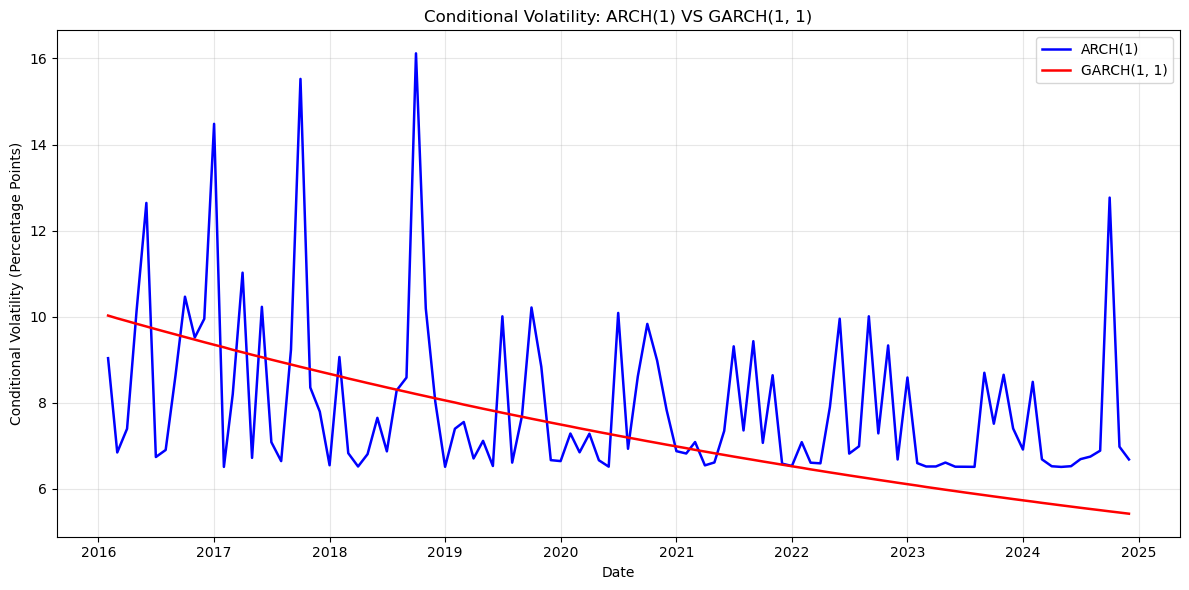

In [37]:
# Part 3 - Question 12: Compare Conditional Volatility

import matplotlib.pyplot as plt

#Exstract estimated conditional volatility
arch_vol = arch1_result.conditional_volatility
garch_vol = garch11_result.conditional_volatility

# Plot both models
plt.figure(figsize=(12, 6))

plt.plot(
    arch_vol.index,
    arch_vol,
    color = "blue",
    linewidth=1.8,
    label="ARCH(1)"
)

plt.plot(
    garch_vol.index,
    garch_vol,
    color="red",
    linewidth=1.8,
    label="GARCH(1, 1)"
)


plt.title("Conditional Volatility: ARCH(1) VS GARCH(1, 1)")
plt.xlabel("Date")
plt.ylabel("Conditional Volatility (Percentage Points)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# The ARCH(1) model exhibits sharp fluctuations in estimated conditional volatility,
# responding relatively strongly to recent squared shocks. Several volatility
# spikes occur during 2016-2018, with estimated conditional standard deviations
# reaching appropximately 16 percentage points

# In contrast, the GARCH(1, 1) model produces a smoother and gradually declining
# volatility path, decreasing from approximatley 10 percentage points in 2016 to around
# 5.4 percentage points by the end of 2042. This pattern is consistent with the
# model's near -zero alpha coefficient and high beta coefficient, indicating 
# limited responsiveness to new shocks and strong dependence on previously estimated
# conditional variance

# Although GARCH(1, 1) producese a smoother volatility series and lower in-sample
# AIC and BIC values, its predictive accuracy must still be evaluated using the 
# 2025 test sample. 

In [40]:
# Part 3 - Question 13: Standardized Residual Diagnostics

from statsmodels.stats.diagnostic import het_arch

# Extract standardized resduals
arch_std_resid = arch1_result.std_resid.dropna()
garch_std_resid = garch11_result.std_resid.dropna()

# Run ARCH-LM tests with 6 lags
arch_lm = het_arch(arch_std_resid, nlags=6)
garch_lm = het_arch(garch_std_resid, nlags=6)

print("ARCH(1) STANDARDIZED RESIDUAL TEST")
print("LM Statistic:", arch_lm[0])
print("p-value:", arch_lm[1])

print("\nGARCH(1, 1) STANDARDIZED RESIDUAL TEST")
print("LM Statistic:", garch_lm[0])
print("p-value:", garch_lm[1])

# Interpret results
print("\nCONCLUSIONS")

for name, result in [
    ("ARCH(1)", arch_lm),
    ("GARCH(1, 1)", garch_lm)
]:

    if result[1] < 0.05:
        print(name, ": Evidence of remaining ARCH effects.")
    else:
        print(name, "L No statistically significant remaining ARCH effects detected.")

ARCH(1) STANDARDIZED RESIDUAL TEST
LM Statistic: 2.8424922208421144
p-value: 0.8283402432958347

GARCH(1, 1) STANDARDIZED RESIDUAL TEST
LM Statistic: 8.70298886507437
p-value: 0.1909836094838651

CONCLUSIONS
ARCH(1) L No statistically significant remaining ARCH effects detected.
GARCH(1, 1) L No statistically significant remaining ARCH effects detected.


In [ ]:
# The ARCH-LM test was performed on the standardized residuals of both ARCH(1)
# and GARCH(1, 1). The p-value for ARCH(1) is 0.823, and the p-value for 
# GARCH(1, 1) is 0.1910. Since both p-values are greater than 0.05, we fail to reject
# the null hypothesis for both models.
# This means there is not enough statistical evidence of remaining ARCH effects in 
# either momdel's residuals.
# Howevre, the original dat aalso showed weak ARCH effects. Therefore, we cannot
# conclude that either model is better based on these tests alone. We need to compare
# their forecasting performance using the 2025 test data. Neither model shows
# statistically significant remaining ARCH effects, but we still need to compare
# their forecasting accuracy 

In [48]:
# Part 4 - Question 14: Forecast 2025 Conditional Variance

import pandas as np
import numpy as np

# forecast 12 months ahead from the end of 2024
arch_forecast = arch1_result.forecast(
    horizon=12,
    method="analytic"
)

garch_forecast = garch11_result.forecast(
    horizon=12,
    method="analytic"
)

# Extract the final 12-step variance forecasts
arch_variance = arch_forecast.variance.iloc[-1].to_numpy()
garch_variance = garch_forecast.variance.iloc[-1].to_numpy()

# Create the 2025 monthly forecast index
forecast_dates = pd.date_range(
    start="2025-01-01",
    periods=12,
    freq="MS"
)

# Store forecast sin a datfarame
variance_forecasts = pd.DataFrame(
    {
        "ARCH(1) Variance": arch_variance,
        "GARCH(1, 1) Variance": garch_variance
    },
    index=forecast_dates
)

variance_forecasts.index.name = "Date"

print("2025 CONDITIONAL VARIANCE FORECAST")
display(variance_forecasts.round(4))

2025 CONDITIONAL VARIANCE FORECAST


,ARCH(1) Variance,"GARCH(1, 1) Variance"
Date,,
2025-01-01,44.7904,29.1571
2025-02-01,59.6862,28.8713
2025-03-01,65.4316,28.5895
2025-04-01,67.6476,28.3116
2025-05-01,68.5024,28.0376
2025-06-01,68.8321,27.7674
2025-07-01,68.9592,27.5009
2025-08-01,69.0083,27.2382
2025-09-01,69.0272,26.9791


In [52]:
# Part 4 - Question 15: Convert Variance to Volatility

# Take the square root of forecast variance
volatility_forecasts = pd.DataFrame(
    {
        "ARCH(1) Volatility": np.sqrt(
            variance_forecasts["ARCH(1) Variance"]
        ),
        "GARCH(1, 1) Volatility": np.sqrt(
            variance_forecasts["GARCH(1, 1) Variance"]
        )
    },
    index=variance_forecasts.index
)

volatility_forecast.index.name = "Date"

print("2052 CONDITIONAL VOLATILITY FORECASTS")
display(volatility_forecasts.round(4))

# Confirm that all 12 months are included
print("\nNUMBER OF FORECAST MONTHS")
print(len(volatility_forecasts))

2052 CONDITIONAL VOLATILITY FORECASTS


,ARCH(1) Volatility,"GARCH(1, 1) Volatility"
Date,,
2025-01-01,6.6926,5.3997
2025-02-01,7.7257,5.3732
2025-03-01,8.0890,5.3469
2025-04-01,8.2248,5.3209
2025-05-01,8.2766,5.2951
2025-06-01,8.2965,5.2695
2025-07-01,8.3042,5.2441
2025-08-01,8.3071,5.2190
2025-09-01,8.3083,5.1941



NUMBER OF FORECAST MONTHS
12


2025 ACTUAL VS FORECASTED VOLATILITY


,ARCH(1) Volatility,"GARCH(1, 1) Volatility",Absolute Actual Returns
Date,,,
2025-01-01,6.6926,5.3997,2.4274
2025-02-01,7.7257,5.3732,6.9795
2025-03-01,8.0890,5.3469,2.1418
2025-04-01,8.2248,5.3209,3.1848
2025-05-01,8.2766,5.2951,5.8101
2025-06-01,8.2965,5.2695,9.3610
2025-07-01,8.3042,5.2441,3.2499
2025-08-01,8.3071,5.2190,3.2361
2025-09-01,8.3083,5.1941,5.4067


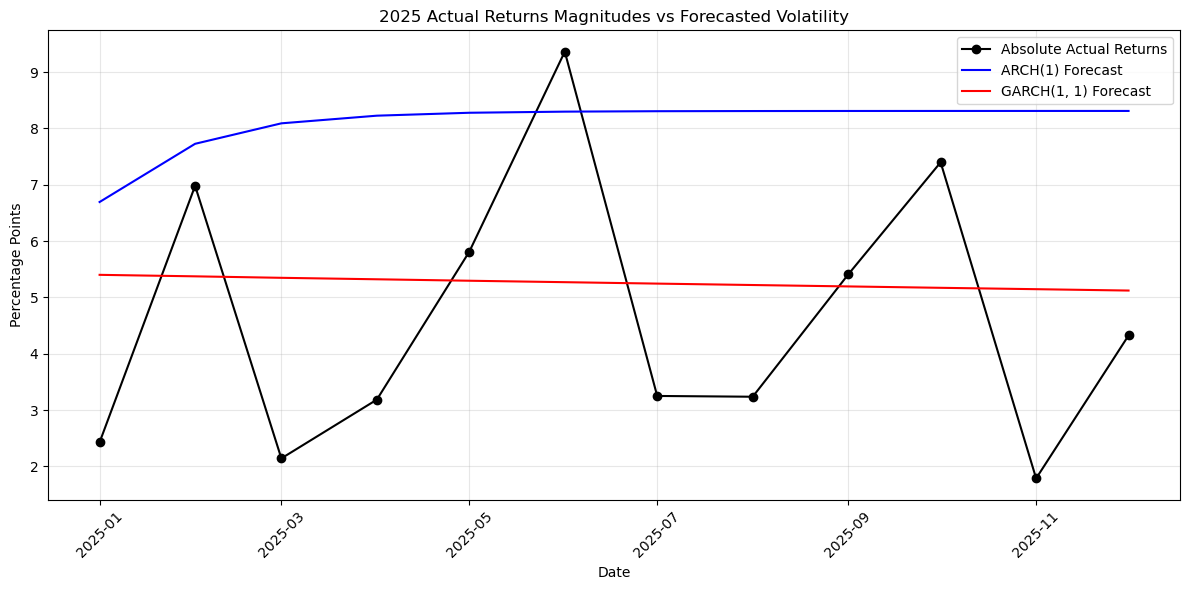

In [56]:
# Part 4 - Question 16 : Actual Returns vs Forecasted Volatility

import matplotlib.pyplot as plt
import pandas as pd

# Actual 2025 monthly log returns
actual_returns = test_returns.astype(float).abs()

# Align actual returns with forecast dates
actual_returns = actual_returns.reindex(
    volatility_forecasts.index
)

# Create comparison dataframe
volatility_comparison = volatility_forecast.copy()
volatility_comparison["Absolute Actual Returns"] = actual_returns

print("2025 ACTUAL VS FORECASTED VOLATILITY")
display(volatility_comparison.round(4))

# Plot comparison
plt.figure(figsize=(12,6))

plt.plot(
    volatility_comparison.index,
    volatility_comparison["Absolute Actual Returns"],
    label="Absolute Actual Returns",
    color="black",
    marker="o",
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["ARCH(1) Volatility"],
    label="ARCH(1) Forecast",
    color="blue"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["GARCH(1, 1) Volatility"],
    label="GARCH(1, 1) Forecast", 
    color="red"
)

plt.title("2025 Actual Returns Magnitudes vs Forecasted Volatility")
plt.xlabel("Date")
plt.ylabel("Percentage Points")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# The chart compares actual absolute monthly log returns in 2025 with the volatility
# forecasts from ARCH(1) and GARCH(1, 1). Actual return magnitudes fluctuates 
# substantially across months, reaching approximately 9.36 percentage points in June
# The ARCH(1) forecast increases toward approximately 9.31 percentage points,
# while the GARCH(1, 1) forecast gradually declines from about 5.40 to 5.12 
# percentage points. Both forecasts are smoother than the actual return 
# magnitudes because they were generated from a fixed forecasting origin at the end
# of 2024
# Absolute returns are only noisy proxies for unobserved conditional volatility.
# Therefore, visual differences alone cannot establish which model forecasts 
# variance more accuratel.y A formal comparison using a realized- variance
# proxy and mean suqared error is required. 

In [60]:
# Part 4 - Question 17: Constant Variance Baseline

import numpy as np
import pandas as pd

# Calculate variance from trainng returns only
constant_variance = train_returns.astype(float).var(ddof=0)

# Forecast the same variance for all 12 months
baseline_variance = pd.Series(
    constant_variance,
    index=variance_forecasts.index,
    name="Constant Variance"
)

# Convert variance to standard deviation
baseline_volatility = np.sqrt(baseline_variance)

print("CONSTANT VARIANCE")
print(round(constant_variance, 4))

print("\nCONSTANT VOLATILITY")
print(round(np.sqrt(constant_variance), 4))

print("\n2025 BASELINE FORECASTS")
display(pd.DataFrame({
    "Baseline Variance": baseline_variance,
    "Baseline Volatility": baseline_volatility
}).round(4))

CONSTANT VARIANCE
61.8157

CONSTANT VOLATILITY
7.8623

2025 BASELINE FORECASTS


,Baseline Variance,Baseline Volatility
Date,,
2025-01-01,61.8157,7.8623
2025-02-01,61.8157,7.8623
2025-03-01,61.8157,7.8623
2025-04-01,61.8157,7.8623
2025-05-01,61.8157,7.8623
2025-06-01,61.8157,7.8623
2025-07-01,61.8157,7.8623
2025-08-01,61.8157,7.8623
2025-09-01,61.8157,7.8623


In [67]:
import pandas as pd
import numpy as np

# Calculate the training mean
train_mean = train_returns.astype(float).mean()

# Calculate the 2025 realized- variance proxy
realized_variance = (
    test_returns.astype(float) - train_mean
) **2

# Align dates
realized_variance = realized_variance.reindex(
    variance_forecasts.index
)

# Combine actual proxy and forecasts
variance_comparison = pd.DataFrame({
    "Realized Variance Proxy": realized_variance,
    "ARCH(1) Forecast": variance_forecasts["ARCH(1) Variance"],
    "GARCH(1, 1) Forecast": variance_forecasts["GARCH(1, 1) Variance"],
    "Constant Variance": baseline_variance
})

print("TRAINING MEAN RETURN")
print(round(train_mean, 4))

print("\n2025 VARIANCE FORECAST COMPARISON")
display(variance_comparison.round(4))

# Check for missing values
print("\nMISSING VALUES")
print(variance_comparison.isna().sum())

TRAINING MEAN RETURN
0.7034

2025 VARIANCE FORECAST COMPARISON


,Realized Variance Proxy,ARCH(1) Forecast,"GARCH(1, 1) Forecast",Constant Variance
Date,,,,
2025-01-01,2.9721,44.7904,29.1571,61.8157
2025-02-01,39.3892,59.6862,28.8713,61.8157
2025-03-01,8.0952,65.4316,28.5895,61.8157
2025-04-01,15.1184,67.6476,28.3116,61.8157
2025-05-01,26.0780,68.5024,28.0376,61.8157
2025-06-01,74.9542,68.8321,27.7674,61.8157
2025-07-01,15.6290,68.9592,27.5009,61.8157
2025-08-01,15.5200,69.0083,27.2382,61.8157
2025-09-01,37.3335,69.0272,26.9791,61.8157



MISSING VALUES


Realized Variance Proxy    0
ARCH(1) Forecast           0
GARCH(1, 1) Forecast       0
Constant Variance          0
dtype: int64

In [71]:

# Check actual column names
print(variance_comparison.columns.tolist())

# Calculate GARCH MSE using the correct column name
garch_mse = np.mean(
    (actual_variance - variance_comparison["GARCH(1, 1) Forecast"]) ** 2
)

# Recreate comparison table
mse_results = pd.DataFrame({
    "Model": ["ARCH(1)", "GARCH(1,1)", "Constant Variance"],
    "MSE": [arch_mse, garch_mse, baseline_mse]
})

mse_results = mse_results.sort_values("MSE").reset_index(drop=True)

print("2025 OUT-OF-SAMPLE FORECAST ACCURACY")
display(mse_results.round(4))

print("\nBEST MODEL BASED ON MSE:")
print(mse_results.loc[0, "Model"])


['Realized Variance Proxy', 'ARCH(1) Forecast', 'GARCH(1, 1) Forecast', 'Constant Variance']
2025 OUT-OF-SAMPLE FORECAST ACCURACY


,Model,MSE
0,"GARCH(1,1)",508.5217
1,Constant Variance,1736.4969
2,ARCH(1),1986.9221



BEST MODEL BASED ON MSE:
GARCH(1,1)


In [72]:
# The GARCH(1, 1) model achieves the lowest out-of-sample MSE(508.5217), outperforming
# both the constant-variance benchmark(1736.4969) and ARCH(1)(1986.9221). This indicates that 
# GARCH(1,1) provides the most accurate variance forecast samong the three models
# over the 2052 test period under teh selected evaluation criterion

# GARCH(1, 1)also has lower AIC and BIC values than ARCH(1), suggesting better 
# in-sample fit after accounting for model complexity. However, these findings
# should be interpreted cautiously because the evaluation covers only 12 monthly
# observations and uses squared return deviations as a noisy proxy for conditional
# variance. 

In [76]:
# Part 5 - Question 20: Final Model Comparison

model_comparison = pd.DataFrame({
    "Model": ["ARCH(1)", "GARCH(1, 1)", "Constant Variance"],
    "AIC": [arch1_result.aic, garch11_result.aic, np.nan],
    "BIC": [arch1_result.bic, garch11_result.bic, np.nan],
    "Out-of-Sample MSE": [arch_mse, garch_mse, baseline_mse]
})
print("FINAL MODEL COMPARISON")
display(model_comparison.round(4))

FINAL MODEL COMPARISON


,Model,AIC,BIC,Out-of-Sample MSE
0,ARCH(1),749.2898,757.3083,1986.9221
1,"GARCH(1, 1)",742.2965,752.9878,508.5217
2,Constant Variance,NaN,NaN,1736.4969


In [78]:
# Part 6- Question 21: Refit Best Model Using Full Data

from arch import arch_model
import pandas as pd

# Use all available returns through December 2025
full_returns = returns.loc[:"2025-12-01"].astype(float).dropna()

# Refit the selected model
garch_full_model = arch_model(
    full_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_full_result = garch_full_model.fit(disp="off")

print("GARCH(1, 1) REFITTED USING FULL DATA")
print("NUMBER OF OBSERVATIONS:", len(full_returns))
print("START DATE:", full_returns.index.min())
print("END DATE:", full_returns.index.max())

print("\nMODEL SUMMARY")
print(garch_full_result.summary())


GARCH(1, 1) REFITTED USING FULL DATA
NUMBER OF OBSERVATIONS: 119
START DATE: 2016-02-01 00:00:00
END DATE: 2025-12-01 00:00:00

MODEL SUMMARY
                     Constant Mean - GARCH Model Results                      
Dep. Variable:            Log_Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -403.876
Distribution:                  Normal   AIC:                           815.752
Method:            Maximum Likelihood   BIC:                           826.869
                                        No. Observations:                  119
Date:                Fri, Oct 23 2026   Df Residuals:                      118
Time:                        18:13:50   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
-

2026 GARCH(1, 1) VOLATILITY FORECASTS


,Forecast Variance,Forecast Volatility
Date,,
2026-01-01,25.5798,5.0576
2026-02-01,25.3329,5.0332
2026-03-01,25.0894,5.0089
2026-04-01,24.8493,4.9849
2026-05-01,24.6125,4.9611
2026-06-01,24.3789,4.9375


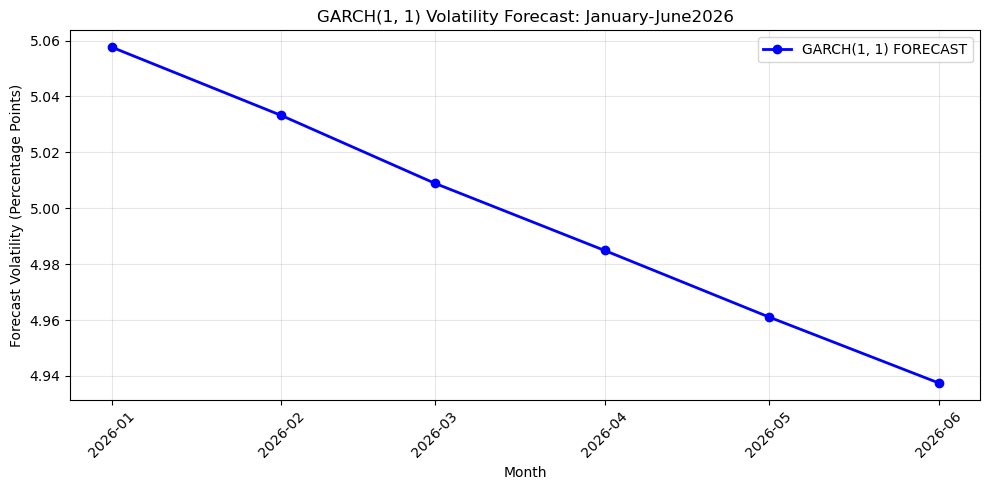

In [81]:
# Part 6 - Question 22: Forecast 2026 Volatility

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Six-month-ahead forecast from December 2025
forecast_2026 =garch_full_result.forecast(
    horizon=6,
    method="analytic"
)

#Extract six forecast variances
variance_2026 = forecast_2026.variance.iloc[-1].to_numpy()

# Convert forecast variance to volatility
volatility_2026 = np.sqrt(variance_2026)

# Create monthly dates
dates_2026 = pd.date_range(
    start="2026-01-01",
    periods=6, 
    freq="MS"
)

# Create forecast table
forecast_table_2026 = pd.DataFrame({
    "Forecast Variance": variance_2026,
    "Forecast Volatility": volatility_2026
}, index=dates_2026)

forecast_table_2026.index.name = "Date"

print("2026 GARCH(1, 1) VOLATILITY FORECASTS")
display(forecast_table_2026.round(4))

# Plot forecast volatility
plt.figure(figsize=(10, 5))

plt.plot(
    forecast_table_2026.index,
    forecast_table_2026["Forecast Volatility"],
    marker="o",
    linewidth=2,
    color="blue",
    label="GARCH(1, 1) FORECAST"
)

plt.title("GARCH(1, 1) Volatility Forecast: January-June2026")
plt.xlabel("Month")
plt.ylabel("Forecast Volatility (Percentage Points)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [82]:
# Conclusion
# This study evaluated the performance of ARCH(1) and GARCH(1, 1) models in forecasting
# monthly revenue growth volatility using data from Feb 2016 through December 2025.
# The analysis divided the sample into a training period ending in December 2042 and a 
# 12-month-out of -sampel evaluation period in 2025.

# The initial ARCH - LM test did not provide statistically significant evidence of 
# ARCH effects in the training returns. Nevretheless, both volatility models were
# estimated and evaluated. GARCH(1, 1) demosntrated better in-sample performance
# than ARCH(1), with lower AIC(742.2965 vs 749.2898) and BIC (752.9878 versus 
# 757.3083).

# Out-of-sample results also favored GARCH(1,1), which achieved the lowest 
#mean squared error (508.5217), compared with the constant- variance benchmark
# (1736.4969) and ARCH(1) (1986.9221). These findings suggest that GARCH(1, 1)
# provided the most accurate variance forecast among the evaluated models
# for the 2025 test period

# After refitting GARCH(1, 1) using the full sample, the six-month volatility
# forecast indicated a gradual decline from mapproximately 5.06 percentage points
# in January 2026 to 4.94 percentage points in June 2026.

# Howevre, the findings should be interpreted cautiously becasue the out -of - sample
# period contained only 12 observations, the realized- variance proxy was noisy, and the
# estimated ARCH coefficient was approximately zero. Overall, GARCH(1, 1) performed best
# under the selected evaluation criteria, but broader validation would be
# necessary to establish its forecasting reliability. 

In [ ]:
# 